# EDA & Feature Engineering

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
import warnings, sys, os

warnings.filterwarnings('ignore')

## 1  Load data

In [19]:
DATA = os.path.join('..', 'data')
train = pd.read_csv(os.path.join(DATA, 'train.csv'))
test  = pd.read_csv(os.path.join(DATA, 'test.csv'))
print('Train:', train.shape, '  Test:', test.shape)
train.head()

Train: (891, 12)   Test: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [20]:
print('Train missing')
print(train.isnull().sum()[train.isnull().sum() > 0])
print('\nTest missing')
print(test.isnull().sum()[test.isnull().sum() > 0])

Train missing
Age         177
Cabin       687
Embarked      2
dtype: int64

Test missing
Age       86
Fare       1
Cabin    327
dtype: int64


## 2  EDA

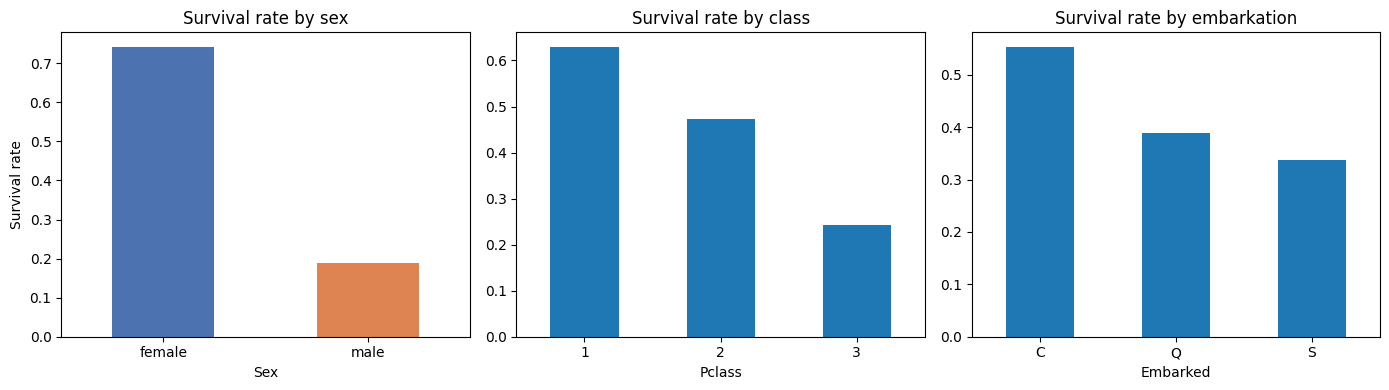

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

train.groupby('Sex')['Survived'].mean().plot(kind='bar', ax=axes[0], color=['#4C72B0','#DD8452'], rot=0)
axes[0].set_title('Survival rate by sex')
axes[0].set_ylabel('Survival rate')

train.groupby('Pclass')['Survived'].mean().plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title('Survival rate by class')

train.groupby('Embarked')['Survived'].mean().plot(kind='bar', ax=axes[2], rot=0)
axes[2].set_title('Survival rate by embarkation')

plt.tight_layout()
plt.show()

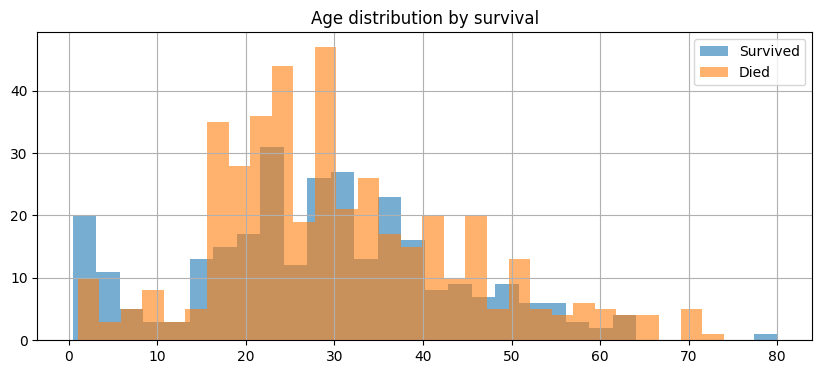

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
train[train['Survived']==1]['Age'].dropna().hist(bins=30, alpha=0.6, label='Survived', ax=ax)
train[train['Survived']==0]['Age'].dropna().hist(bins=30, alpha=0.6, label='Died', ax=ax)
ax.set_title('Age distribution by survival')
ax.legend()
plt.show()

## 3  Feature engineering

In [23]:
sys.path.insert(0, os.path.join('..', 'scripts'))
from feature_engineering import process_data

In [24]:
train['Title'] = train['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
print(train.groupby('Title')['Survived'].agg(['mean','count']).sort_values('count', ascending=False).head(12))

              mean  count
Title                    
Mr        0.156673    517
Miss      0.697802    182
Mrs       0.792000    125
Master    0.575000     40
Dr        0.428571      7
Rev       0.000000      6
Mlle      1.000000      2
Major     0.500000      2
Col       0.500000      2
Capt      0.000000      1
Lady      1.000000      1
Countess  1.000000      1


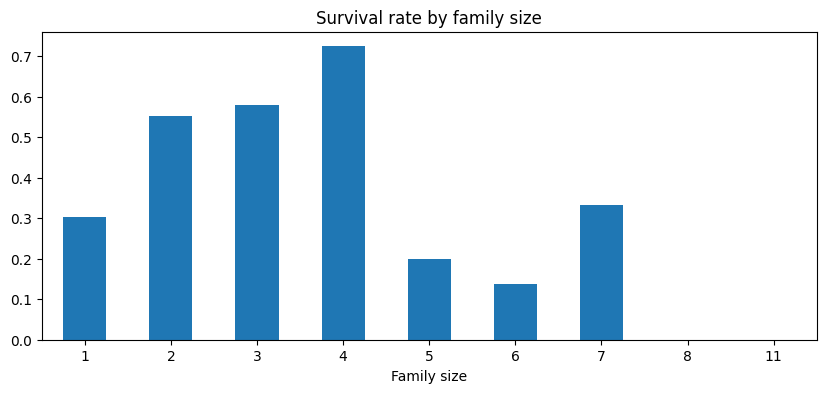

In [25]:
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1
fig, ax = plt.subplots(figsize=(10, 4))
train.groupby('FamilySize')['Survived'].mean().plot(kind='bar', ax=ax, rot=0)
ax.set_title('Survival rate by family size')
ax.set_xlabel('Family size')
plt.show()

In [26]:
train['CabinKnown'] = train['Cabin'].notna().astype(int)
print('Survival rate with/without cabin record:')
print(train.groupby('CabinKnown')['Survived'].mean())

Survival rate with/without cabin record:
CabinKnown
0    0.299854
1    0.666667
Name: Survived, dtype: float64


## 4  Pipeline & train model

In [27]:
train_raw = pd.read_csv(os.path.join(DATA, 'train.csv'))
test_raw  = pd.read_csv(os.path.join(DATA, 'test.csv'))
passenger_ids = test_raw['PassengerId']  # save before process_data drops it

train_eng, test_eng = process_data(train_raw, test_raw)

X = train_eng.drop(columns=['Survived'])
y = train_eng['Survived']
X_test = test_eng
FEATURES = list(X.columns)

print('Feature matrix shape:', X.shape)
print('Features used:', FEATURES)

Feature matrix shape: (891, 7)
Features used: ['Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'Family_Survival', 'Title']


In [28]:
model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
print(f'CV accuracy: {scores.mean():.4f} ± {scores.std():.4f}')

CV accuracy: 0.8507 ± 0.0183


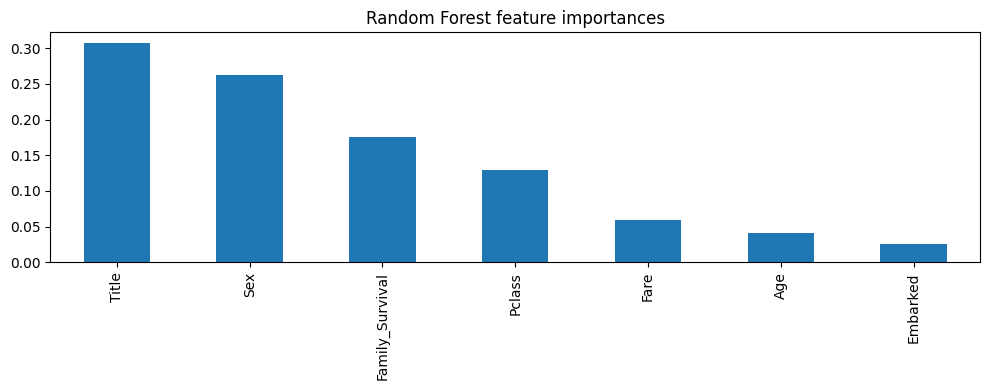

In [29]:
model.fit(X, y)
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
imp.plot(kind='bar', figsize=(10, 4), title='Random Forest feature importances')
plt.tight_layout()
plt.show()

In [30]:
preds = model.predict(X_test)

submission = pd.DataFrame({'PassengerId': passenger_ids, 'Survived': preds.astype(int)})
sub_path = os.path.join(DATA, 'gender_submission.csv')
submission.to_csv(sub_path, index=False)
print(f'Predicted survivors: {preds.sum()} / {len(preds)}')

Predicted survivors: 149.0 / 418
